# 🧩 Notebook 5 — Step Growth & Gelation
| | |
|---|---|
| ⏱ Time | ~30 min |
| 🎯 You will learn | pick *two* molecules and join them · Carothers & Flory checks · first taste of **time** (Gillespie) · find the **gel point** with a Disjoint-Set (DSU) |
| 📖 Book algorithms | *Step-Growth of AA and BB* · *Gillespie for Step-Growth* · *AB + A₃ Branching* · *Step-Growth with Arbitrary Monomer Mixtures (DSU)* |

Chain growth (Notebooks 2–4) adds monomers one by one. **Step growth** is different: *any* two molecules with matching ends (A + B) can link. Details and theory: *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
random.seed(5)
plt.rcParams.update({"figure.figsize": (6, 3.6), "axes.grid": True, "grid.alpha": 0.3})

## 1 · AA + BB: "pick two, check the ends, join"
Each molecule is stored as `[length, end1, end2]`. A diacid (AA) is `[1, 'A', 'A']`, a diol (BB) is `[1, 'B', 'B']`.

Each step: pick two different molecules at random, pick one end of each. If one end is A and the other B → **link** (else nothing happens, try again).

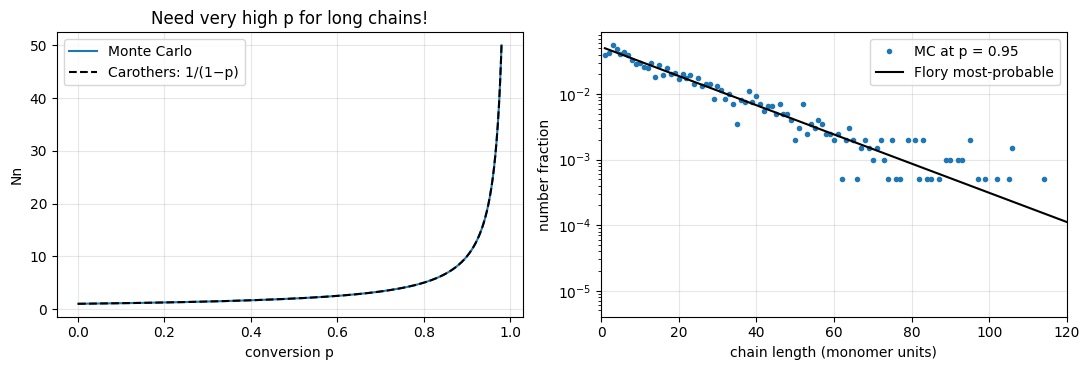

In [2]:
def step_growth_AABB(N0, p_stop=0.98, p_snapshot=0.95):
    pool = [[1, "A", "A"] for _ in range(N0)] + [[1, "B", "B"] for _ in range(N0)]
    nuA0 = nuA = 2 * N0
    p_hist, Nn_hist, snapshot = [], [], None
    while 1 - nuA/nuA0 < p_stop:
        i, j = random.sample(range(len(pool)), 2)          # two different molecules
        ei, ej = random.randint(1, 2), random.randint(1, 2) # one end of each
        if pool[i][ei] != pool[j][ej]:                      # A meets B → react
            new = [pool[i][0] + pool[j][0], pool[i][3 - ei], pool[j][3 - ej]]
            pool[i] = new
            pool[j] = pool[-1]; pool.pop()                  # remove j quickly
            nuA -= 1
            p = 1 - nuA/nuA0
            p_hist.append(p); Nn_hist.append(2*N0 / len(pool))
            if snapshot is None and p >= p_snapshot:
                snapshot = np.array([m[0] for m in pool])
    return np.array(p_hist), np.array(Nn_hist), snapshot

p, Nn, snap = step_growth_AABB(20_000)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(p, Nn, label="Monte Carlo"); ax[0].plot(p, 1/(1-p), "k--", label="Carothers: 1/(1−p)")
ax[0].set_xlabel("conversion p"); ax[0].set_ylabel("Nn"); ax[0].legend(); ax[0].set_title("Need very high p for long chains!")
cnt = np.bincount(snap)[1:]; nn = np.arange(1, len(cnt) + 1)
ax[1].semilogy(nn, cnt/cnt.sum(), ".", label="MC at p = 0.95")
ax[1].semilogy(nn, 0.05*0.95**(nn-1), "k-", label="Flory most-probable")
ax[1].set_xlim(0, 120); ax[1].set_xlabel("chain length (monomer units)"); ax[1].set_ylabel("number fraction"); ax[1].legend()
plt.tight_layout(); plt.show()

## 2 · Adding a clock: Gillespie for step growth
So far we only know *what* happened, not *when*. Trick #4 from Notebook 1 adds the time:
- total rate (propensity) `a = k_MC · n_A · n_B`, with `k_MC = k / (N_A·V)`
- waiting time `τ = ln(1/Rnd) / a`

For equal amounts of A and B, theory says `1/(1−p) = 1 + k[A]₀ t` → a straight line.

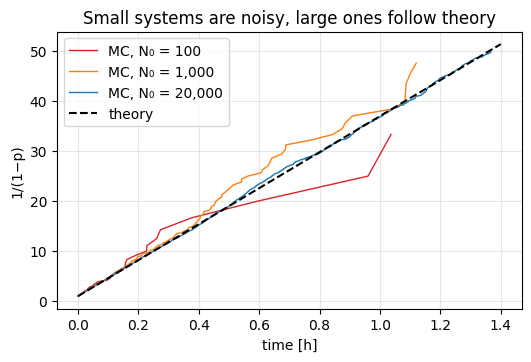

In [3]:
NA = 6.022e23

def gillespie_step_growth(N0, k, A0):
    V = N0 / (A0 * NA)                      # volume that contains N0 groups
    kMC = k / (NA * V)
    nA = nB = N0; t = 0.0
    sizes = [1] * N0
    ts, ps = [0.0], [0.0]
    while nA > 1:
        a = kMC * nA * nB
        t += np.log(1/random.random()) / a  # Trick #4
        i, j = random.sample(range(len(sizes)), 2)
        sizes[i] += sizes[j]; sizes[j] = sizes[-1]; sizes.pop()
        nA -= 1; nB -= 1
        ts.append(t); ps.append(1 - nA/N0)
    return np.array(ts), np.array(ps)

k, A0 = 1e-2, 1.0          # L/(mol·s), mol/L
for N0, c in [(100, "tab:red"), (1000, "tab:orange"), (20_000, "tab:blue")]:
    t, p = gillespie_step_growth(N0, k, A0)
    m = p < 0.98
    plt.plot(t[m]/3600, 1/(1-p[m]), c=c, lw=1, label=f"MC, N₀ = {N0:,}")
tt = np.linspace(0, 1.4, 50)
plt.plot(tt, 1 + k*A0*tt*3600, "k--", label="theory")
plt.xlabel("time [h]"); plt.ylabel("1/(1−p)"); plt.legend(); plt.title("Small systems are noisy, large ones follow theory"); plt.show()

## 3 · Branching monomers: AB + A₃ (star-like polymers)
Add a few A₃ "core" molecules to an AB monomer. Rules (book: *Sequential Event Sampling for AB + A₃*): pick a molecule with a free A and one with a free B, they must be different molecules and not both contain a core.

Prediction: once all B groups are used, every molecule is attached to a core → `Nn` stops growing at `N₀ / n_A3`.

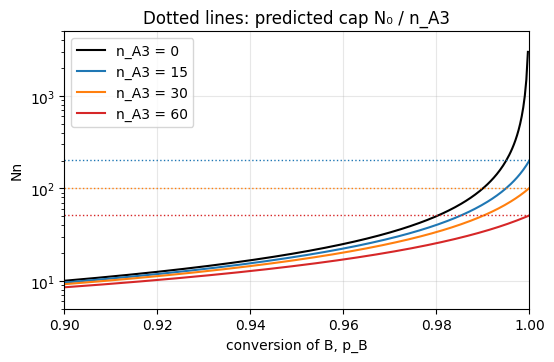

In [4]:
class Bag:
    """A set with O(1) add / remove / random pick."""
    def __init__(self): self.items, self.pos = [], {}
    def add(self, x):
        if x not in self.pos: self.pos[x] = len(self.items); self.items.append(x)
    def remove(self, x):
        if x in self.pos:
            k = self.pos.pop(x); last = self.items.pop()
            if last != x: self.items[k] = last; self.pos[last] = k
    def pick(self): return random.choice(self.items)
    def __len__(self): return len(self.items)

def ab_a3(n_AB, n_A3, pB_target=1.0):
    N0 = n_AB + n_A3
    nA   = [1]*n_AB + [3]*n_A3            # free A groups per molecule
    hasB = [1]*n_AB + [0]*n_A3
    core = [0]*n_AB + [1]*n_A3
    poolA, poolB = Bag(), Bag()
    for m in range(N0):
        poolA.add(m)
        if hasB[m]: poolB.add(m)
    nuB0, chains, traj = n_AB, N0, []
    while len(poolB) and 1 - len(poolB)/nuB0 < pB_target:
        for _ in range(1000):
            i, j = poolA.pick(), poolB.pick()
            if i != j and not (core[i] and core[j]): break
        else:
            break                                    # no valid pair left
        nA[i] += nA[j] - 1; core[i] += core[j]       # merge j into i (A of i + B of j)
        for pool in (poolA, poolB): pool.remove(j)
        if nA[i] == 0: poolA.remove(i)
        chains -= 1
        traj.append((1 - len(poolB)/nuB0, N0/chains))   # (p_B, Nn)
    return np.array(traj)

for n_A3, c in [(0, "k"), (15, "tab:blue"), (30, "tab:orange"), (60, "tab:red")]:
    tr = ab_a3(3000, n_A3)
    plt.plot(tr[:, 0], tr[:, 1], c=c, label=f"n_A3 = {n_A3}")
    if n_A3: plt.axhline((3000 + n_A3)/n_A3, c=c, ls=":", lw=1)
plt.yscale("log"); plt.xlim(0.9, 1.0); plt.ylim(5, 5000); plt.xlabel("conversion of B, p_B"); plt.ylabel("Nn")
plt.legend(); plt.title("Dotted lines: predicted cap N₀ / n_A3"); plt.show()

## 4 · Gelation with a Disjoint-Set Union (DSU) 🕸️
With A₂ + B₃ (e.g. a diacid + a triol) a **network** forms: at the *gel point* one giant molecule suddenly spans the system.

Tracking giant molecules by hand is slow. A **DSU** answers "which molecule does this monomer belong to?" almost instantly:
- every monomer points to a "parent"; the top of the chain is the molecule's **root**
- linking two monomers = pointing one root to the other (`union`)

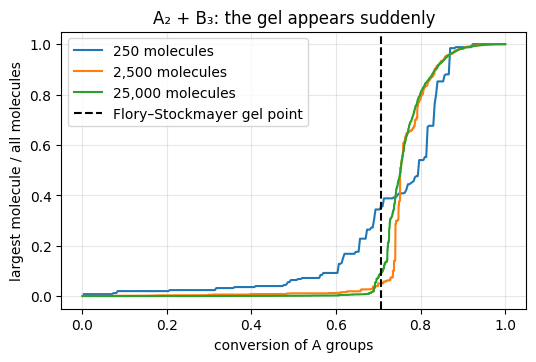

In [5]:
class DSU:
    def __init__(self, n):
        self.parent = list(range(n)); self.size = [1]*n; self.largest = 1
    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]   # path compression (shortcut)
            x = self.parent[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            if self.size[ra] < self.size[rb]: ra, rb = rb, ra
            self.parent[rb] = ra; self.size[ra] += self.size[rb]
            self.largest = max(self.largest, self.size[ra])
        return self.largest

def gelation(fA, nA, fB, nB):
    freeA, freeB, mol = [], [], 0
    for f, cnt, lst in [(fA, nA, freeA), (fB, nB, freeB)]:
        for _ in range(cnt):
            lst.extend([mol] * f); mol += 1          # f copies of the molecule id = f free groups
    dsu, totA = DSU(mol), len(freeA)
    pA, Lfrac = [], []
    while freeA and freeB:
        ia, ib = random.randrange(len(freeA)), random.randrange(len(freeB))
        a, b = freeA[ia], freeB[ib]
        freeA[ia] = freeA[-1]; freeA.pop(); freeB[ib] = freeB[-1]; freeB.pop()
        L = dsu.union(a, b)
        pA.append(1 - len(freeA)/totA); Lfrac.append(L/mol)
    return np.array(pA), np.array(Lfrac)

for scale in [50, 500, 5000]:          # A2 : B3 = 3 : 2 → equal numbers of A and B groups
    pA, L = gelation(2, 3*scale, 3, 2*scale)
    plt.plot(pA, L, label=f"{5*scale:,} molecules")
plt.axvline(1/np.sqrt(2), c="k", ls="--", label="Flory–Stockmayer gel point")
plt.xlabel("conversion of A groups"); plt.ylabel("largest molecule / all molecules")
plt.legend(); plt.title("A₂ + B₃: the gel appears suddenly"); plt.show()

## ✅ Recap
- Step growth = **pick two, check compatibility, merge**.
- Gillespie adds real **time** with one extra line.
- Clever data structures (`Bag`, `DSU`) keep big simulations fast.
- Bigger systems → sharper, more "theory-like" transitions.

### 🧪 Try it yourself
1. Unbalance the AA/BB stoichiometry (e.g. 5000 AA, 4800 BB). What is the maximum Nn?
2. Try A₂ + B₄ in `gelation`. Where should the gel point move? (α_c = 1/√((f_A−1)(f_B−1)))
3. In the Gillespie cell, double `k`. What changes and what doesn't?

➡️ **Next: Notebook 6 — Gillespie kinetic Monte Carlo for free-radical polymerization**